In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model  import LinearRegression
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
import numpy as np 
import matplotlib.pyplot as plt



In [26]:
data={
    "study_hours":[1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "marks":[32, 38, 43, 50, 54, 61, 68, 73, 81, 88]
}
df=pd.DataFrame(data)
df.head()

,study_hours,marks
0,1,32
1,2,38
2,3,43
3,4,50
4,5,54


In [27]:
x=df.iloc[:,[0]].values
y=df.iloc[:,-1].values
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

intercept 24.724137931034484
coefficent 6.163793103448276
mae 0.875
mse 0.7709943519619504
rmse 0.8780628405541089
r2_swuare 0.9983320836085193


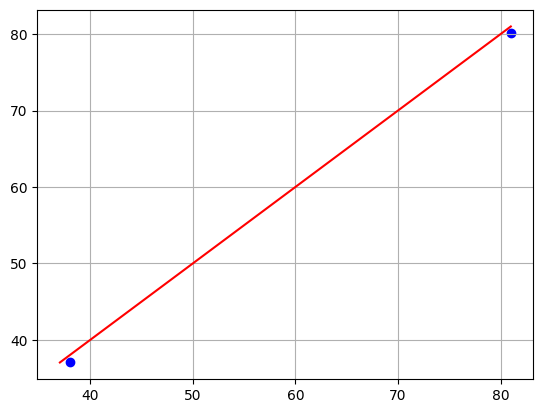

In [ ]:
import numpy as np
model=LinearRegression()
model.fit(x_train,y_train)
y_pred=model.predict(x_test)
print("intercept",model.intercept_)
print("coefficent",model.coef_[0])

linearmae=mean_absolute_error(y_test,y_pred)
linearmse=mean_squared_error(y_test,y_pred)
linearrmse=np.sqrt(mse)
r_square=r2_score(y_test,y_pred)
print("mae",mae)
print("mse",mse)
print("rmse",rmse)
print("r2_swuare",r_square)
plt.scatter(y_test,y_pred,color="blue")
minimum=min(y_test.min(),y_pred.min())
maximum=max(y_test.max(),y_pred.max())
plt.plot(
    [minimum,maximum],
    [minimum,maximum],
    color="red"
)
plt.grid()
plt.show()



In [34]:
from sklearn.linear_model import RidgeCV,Ridge,LassoCV,Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


In [35]:
model=make_pipeline(
    StandardScaler(),
    RidgeCV(alphas=[0.01,0.1,1,10,100])
)

In [37]:
model.fit(x_train,y_train)
ridge_model=model.named_steps["ridgecv"]
print(ridge_model.alpha_)

0.01


In [38]:
model=make_pipeline(
    StandardScaler(),
    Ridge(alpha=0.01)
)
model.fit(x_train,y_train)
y_pred=model.predict(x_test)

In [41]:
ridge_step=model.named_steps["ridge"]
print(ridge_step.intercept_)
print(ridge_step.coef_)

58.625
[16.5758011]


In [42]:
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R-squared:", r2_score(y_test, y_pred))

MAE: 0.875
MSE: 0.7677726674763221
RMSE: 0.8762263791260351
R-squared: 0.9983390531801486


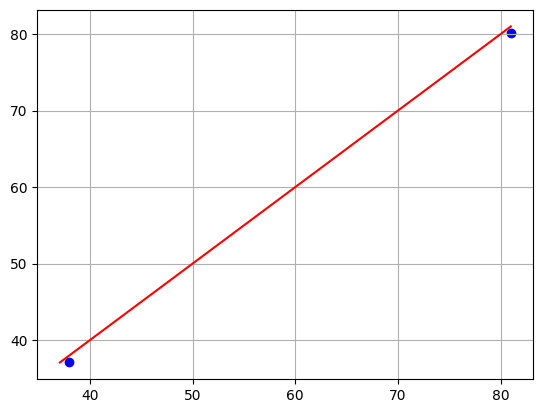

In [43]:
plt.scatter(y_test,y_pred,color="blue")
minimum=min(y_test.min(),y_pred.min())
maximum=max(y_test.max(),y_pred.max())
plt.plot(
    [minimum,maximum],
    [minimum,maximum],
    color="red"
)
plt.grid()
plt.show()

In [44]:
from sklearn.linear_model import Lasso,LassoCV
from sklearn.preprocessing import StandardScaler

In [45]:
model=make_pipeline(
    StandardScaler(),
    LassoCV(alphas=[0.01,0.1,1,10,100])
)
model.fit(x_train,y_train)
ridge_model=model.named_steps["lassocv"]
print(ridge_model.alpha_)

0.01


In [49]:
model=make_pipeline(
    StandardScaler(),
    Lasso(alpha=0.01)
)
model.fit(x_train,y_train)
ridge_model=model.named_steps["lasso"]
y_pred=model.predict(x_test)
print(ridge_model.coef_)
print(ridge_model.intercept_)

[16.58652085]
58.625


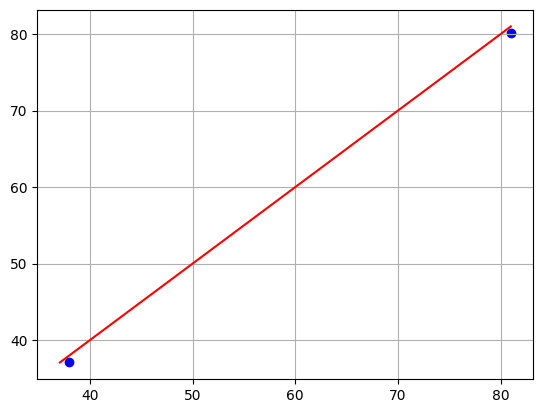

In [50]:
plt.scatter(y_test,y_pred,color="blue")
minimum=min(y_test.min(),y_pred.min())
maximum=max(y_test.max(),y_pred.max())
plt.plot(
    [minimum,maximum],
    [minimum,maximum],
    color="red"
)
plt.grid()
plt.show()